# DSCI 552 HW 7

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

warnings.filterwarnings("ignore")
RANDOM_STATE = 552

### 1a. load data

In [ ]:
frogs = pd.read_csv("../data/Frogs_MFCCs.csv")
features = [c for c in frogs.columns if c.startswith("MFCC")]
labels = ["Family", "Genus", "Species"]

X = frogs[features]
Y = frogs[labels]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.7, random_state=RANDOM_STATE)

print("train:", X_train.shape, "test:", X_test.shape)
for lab in labels:
    print(lab, "classes:", Y[lab].nunique())

train: (5036, 22) test: (2159, 22)
Family classes: 4
Genus classes: 8
Species classes: 10


### 1b. training classifiers per label



In [ ]:
def evaluate(Y_true, Y_pred):
    wrong = (np.asarray(Y_true) != np.asarray(Y_pred))
    hamming_loss = wrong.mean()
    return {"exact match": (~wrong.any(axis=1)).mean(),
            "hamming loss": hamming_loss,
            "hamming score": 1 - hamming_loss}

ii. SVM with Gaussian kernel, SVM with 1 vs all

In [ ]:
C_grid = [0.1, 1, 10, 100, 1000]
sigma_grid = [0.25, 0.5, 0.75, 1, 1.5, 2]
gamma_grid = [1 / (2 * s**2) for s in sigma_grid]

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

def fit_per_label(model, grid):
    fitted, preds, rows = {}, {}, []
    for lab in labels:
        search = GridSearchCV(model, grid, cv=skf, scoring="accuracy", n_jobs=-1)
        search.fit(X_train, Y_train[lab])
        fitted[lab] = search
        preds[lab] = search.predict(X_test)
        rows.append({"label": lab, **search.best_params_,
                     "cv accuracy": search.best_score_,
                     "test accuracy": (preds[lab] == Y_test[lab]).mean()})
    return fitted, pd.DataFrame(preds, index=Y_test.index), pd.DataFrame(rows).set_index("label")

rbf_svm = OneVsRestClassifier(SVC(kernel="rbf"))
rbf_fitted, rbf_pred, rbf_table = fit_per_label(rbf_svm, {"estimator__C": C_grid, "estimator__gamma": gamma_grid})
rbf_table["sigma"] = np.sqrt(1 / (2 * rbf_table["estimator__gamma"]))
display(rbf_table)
pd.Series(evaluate(Y_test, rbf_pred), name="Gaussian SVM (test)").to_frame()

,estimator__C,estimator__gamma,cv accuracy,test accuracy,sigma
label,,,,,
Family,10,2.0,0.994440,0.991663,0.5
Genus,100,2.0,0.991661,0.988884,0.5
Species,10,2.0,0.991262,0.987494,0.5


,Gaussian SVM (test)
exact match,0.986105
hamming loss,0.010653
hamming score,0.989347


iii. L1-penalized SVM


In [ ]:
l1_svm = Pipeline([
    ("scale", StandardScaler()),
    ("svm", LinearSVC(penalty="l1", dual=False, max_iter=20000)),
])
l1_C_grid = {"svm__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

l1_fitted, l1_pred, l1_table = fit_per_label(l1_svm, l1_C_grid)
display(l1_table)
pd.Series(evaluate(Y_test, l1_pred), name="L1 SVM (test)").to_frame()

,svm__C,cv accuracy,test accuracy
label,,,
Family,1,0.937849,0.933302
Genus,10,0.954729,0.952293
Species,1,0.958101,0.956461


,L1 SVM (test)
exact match,0.917554
hamming loss,0.052648
hamming score,0.947352


iv. L1-penalized SVM with SMOTE

In [ ]:
smote_svm = ImbPipeline([
    ("scale", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("svm", LinearSVC(penalty="l1", dual=False, max_iter=20000)),
])

smote_fitted, smote_pred, smote_table = fit_per_label(smote_svm, l1_C_grid)
display(smote_table)
pd.Series(evaluate(Y_test, smote_pred), name="L1 SVM + SMOTE (test)").to_frame()

,svm__C,cv accuracy,test accuracy
label,,,
Family,100.0,0.922758,0.913386
Genus,1.0,0.917197,0.911070
Species,0.1,0.955123,0.950903


,L1 SVM + SMOTE (test)
exact match,0.861973
hamming loss,0.074880
hamming score,0.925120


In [ ]:
summary = pd.DataFrame({
    "Gaussian SVM": evaluate(Y_test, rbf_pred),
    "L1 SVM": evaluate(Y_test, l1_pred),
    "L1 SVM + SMOTE": evaluate(Y_test, smote_pred),
}).T
summary

,exact match,hamming loss,hamming score
Gaussian SVM,0.986105,0.010653,0.989347
L1 SVM,0.917554,0.052648,0.947352
L1 SVM + SMOTE,0.861973,0.074880,0.925120


Takeaways:
- The Gaussian SVM is the strongest with a 98.6% exact match and a hamming loss of only 1.1% on the test set. Each label is above 98.7% test accuracy.
- The L1 (linear) SVM is noticeably worse with a 91.8% exact match and hamming loss of 5.3%. A linear boundary is too simple for these MFCC features, and the Gaussian kernel can pick up the non-linear patterns.
- SMOTE made the L1 SVM worse overall, with a 86.2% exact match and hamming loss of 7.5%. Balancing the classes pushes the model toward the small classes, so it makes more mistakes on the big ones, and these overall measures are dominated by the big classes. SMOTE could still help recall for rare species, but here class imbalance isn't the main problem. Model flexibility (the kernel) matters much more.

### 2. k-means clustering

k chosen from {2, ..., 50} by the highest silhouette score

In [ ]:
X_all = frogs[features].values
Y_all = frogs[labels]

def one_run(seed):
    best_k, best_sil, best_labels = None, -1, None
    for k in range(2, 51):
        km = KMeans(n_clusters=k, n_init=5, random_state=seed).fit(X_all)
        sil = silhouette_score(X_all, km.labels_)
        if sil > best_sil:
            best_k, best_sil, best_labels = k, sil, km.labels_

    clusters = pd.Series(best_labels, index=Y_all.index)
    majority = Y_all.groupby(clusters).agg(lambda s: s.value_counts().idxmax())
    assigned = majority.loc[clusters].set_index(Y_all.index)

    dist = (assigned.values != Y_all.values).sum(axis=1)
    return {"seed": seed, "k": best_k, "hamming distance": dist.mean(),
            "hamming loss": dist.mean() / 3, "hamming score": 1 - dist.mean() / 3}, majority

runs = []
for seed in range(50):
    result, majority = one_run(seed)
    runs.append(result)
    if seed == 0:
        first_majority = majority
mc = pd.DataFrame(runs)

In [ ]:
print("majority label triplets per cluster (run 1):")
display(first_majority)
print("k chosen across runs:", mc["k"].value_counts().to_dict())
mc[["hamming distance", "hamming loss", "hamming score"]].agg(["mean", "std"])

majority label triplets per cluster (run 1):


,Family,Genus,Species
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,Hylidae,Hypsiboas,HypsiboasCordobae
2,Dendrobatidae,Ameerega,Ameeregatrivittata
3,Hylidae,Hypsiboas,HypsiboasCinerascens


k chosen across runs: {4: 50}


,hamming distance,hamming loss,hamming score
mean,0.686204,0.228735,0.771265
std,0.038930,0.012977,0.012977


Silhouette picked k = 4 in all 50 runs, which matches the 4 families. Average hamming distance is 0.686 (std 0.039), hamming loss is 0.229 (std 0.013), and hamming score is 0.771 (std 0.013). With only 4 clusters, k-means is not able to separate all 8 genus classes and 10 species, which is where most of the errors come from.

### 3. ISLR 12.6.2


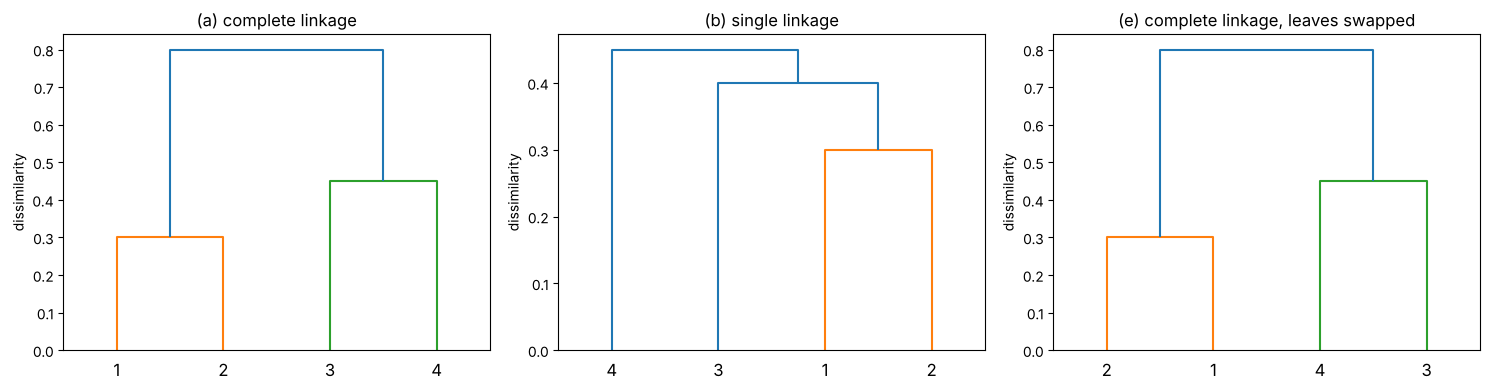

In [ ]:
D = np.array([[0, 0.3, 0.4, 0.7],
              [0.3, 0, 0.5, 0.8],
              [0.4, 0.5, 0, 0.45],
              [0.7, 0.8, 0.45, 0]])
names = ["1", "2", "3", "4"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
dendrogram(linkage(squareform(D), "complete"), labels=names, ax=ax[0])
ax[0].set_title("(a) complete linkage")
dendrogram(linkage(squareform(D), "single"), labels=names, ax=ax[1])
ax[1].set_title("(b) single linkage")

complete = linkage(squareform(D[[1, 0, 3, 2]][:, [1, 0, 3, 2]]), "complete")
dendrogram(complete, labels=["2", "1", "4", "3"], ax=ax[2], distance_sort="ascending")
ax[2].set_title("(e) complete linkage, leaves swapped")
for a in ax:
    a.set_ylabel("dissimilarity")
plt.tight_layout(); plt.show()

a. For complete linkage, 1 and 2 merge first at 0.3. Next, 3 and 4 merge at 0.45 (this is smaller than {1,2}–3 = 0.5 and {1,2}–4 = 0.8). Lastly, {1,2} and {3,4} merge at 0.8 (which is the largest distance between them).

b. For single linkage, 1 and 2 merge first at 0.3. Next, 3 joins {1,2} at 0.4 (the closest distance, from 1 to 3). Lastly, 4 joins at 0.45 (this is the closest distance from 3 to 4).

c. Splitting the complete linkage dendrogram into two clusters gives us {1, 2} and {3, 4}.

d. Splitting the single linkage dendrogram into two clusters gives us {1, 2, 3} and {4}.

e. Swapping the two leaves under each merge (order 2, 1, 4, 3) gives a dendrogram that looks different but means the same thing: the same clusters merge at the same heights. This can be seen on the rightmost plot.